# Assignment 1
Due Sep. 9

Yazdan Zinati 
260928077   

0. To complete the weekly programming challenges, you need to have the scikit-learn (sklearn) python
machine learning library and its dependencies installed (instructions here: https://scikitlearn.org/stable/install.html). Use pyplot for visualization. Importing libraries looks like:

In [115]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline


The tools that you use in this challenge will be useful for all subsequent challenges. While working on
these weekly challenges it is expected that you will have to search the scikit-learn online documentation
for proper function usage – all the information you need will be there.

For this challenge you will use the “breast cancer” toy classification dataset that comes with scikit-learn.
Load the data using:

In [3]:
dataset = load_breast_cancer() # load all the data
print(dataset.keys()) # lists the contents of the dataset
print(dataset.data.shape) # shape of the X matrix

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
(569, 30)


This dataset includes: a data matrix where the rows are subjects and the columns are measured
features; a target vector containing the binary classification of each subject (healthy or diagnosed with
breast cancer); a feature_names array with the names of the features (columns of X).

Note: all plots must have a descriptive title and axis labels. Leaving these out will result in deductions, as
plots that are missing these are practically useless for communicating information.

1. A useful way to quickly visualize a dataset is to use principal component analysis, which finds the axes
of maximum variance in the data. Using sklearn PCA with two components, fit the PCA model to the
data and project it onto the two components (PCA(n_components=2).fit_transform(...)), then
plot this transformed data using a 2D scatterplot (plt.plot(...)). Note that this visualization doesn’t
take the target into account (it is unsupervised).

In [4]:
# 1 is benign, 0 is malignant
print("number of benign cases:", dataset.target.sum())
print("number of malignant cases:", len(dataset.target) - dataset.target.sum())

number of benign cases: 357
number of malignant cases: 212


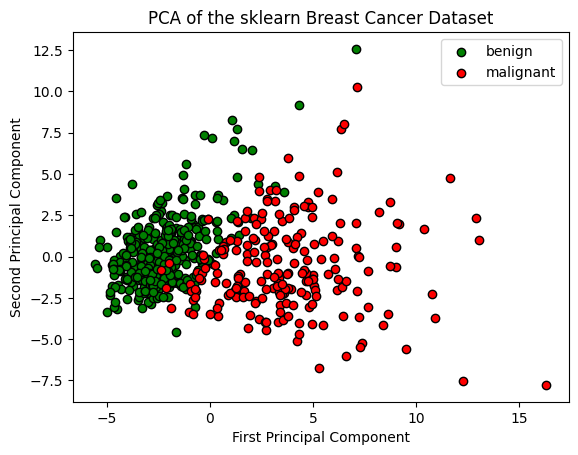

Explained variance ratio: [0.44272026 0.18971182]


In [5]:
# We first start by standardizing the data.
# The below tutorial from sklearn affirms that setting the mean of each feature to zero and scaling to unit variance improves the separability of the classes in PCA. 
# https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html

scaler = StandardScaler()
dataset.data_scaled = scaler.fit_transform(dataset.data)
# now do PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(dataset.data_scaled)

# plot PCA 
plt.figure()

# Create scatter plot for each class (B, M)
class_data = dataset.target == 1
plt.scatter(X_pca[class_data, 0], X_pca[class_data, 1], 
            color="green", label=dataset.target_names[1], edgecolor='black')
class_data = dataset.target == 0
plt.scatter(X_pca[class_data, 0], X_pca[class_data, 1], 
            color="red", label=dataset.target_names[0], edgecolor='black')

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of the sklearn Breast Cancer Dataset')
plt.legend()
plt.show()

# this visualization doesn’t take the target into account (it is unsupervised)
# but we still show the target names in the legend

# Step 6: Check explained variance ratio
print("Explained variance ratio:", pca.explained_variance_ratio_)


2. When training a machine learning model we are often concerned with features that are highly
correlated with each other, as they carry redundant information. Calculate the pearson correlation
(np.corrcoef(..., rowvar=False)will calculate the symmetric correlation matrix, or
scipy.pearsonr(...) also works) between each pair of features/columns, and plot a histogram with
50 bins of the pearson correlations (plt.hist(..., bins=50)). Hints: np.tril(...,k=1) will help
remove the redundant correlation values and np.flatten(...) will convert a 2d array into a 1d array.

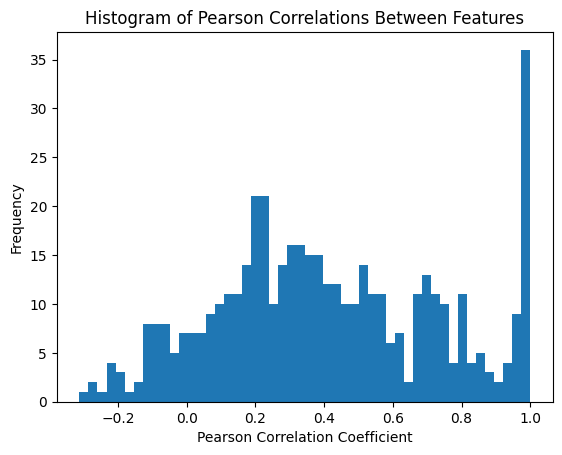

In [39]:
# calculate pearson symmetric correlation matrix
correlation_matrix = np.corrcoef(dataset.data_scaled, rowvar=False)

# verify that we have a 30 by 30 matrix (30 is the number of features or columns in the data matrix)
assert (correlation_matrix.shape[1] == correlation_matrix.shape[0] == dataset.data.shape[1])

# get the lower triangle or the correlation matrix
lower_triangle_cmatrix = np.tril(correlation_matrix, k=0)
lower_triangle_cmatrix = lower_triangle_cmatrix.flatten()
lower_triangle_cmatrix = lower_triangle_cmatrix[lower_triangle_cmatrix != 0] # remove 0 values since they are from the top triangle 

# verify size == (30*30/2 + 30/2)
assert(lower_triangle_cmatrix.shape[0] == len(dataset.feature_names)**2/2 + len(dataset.feature_names)/2)

plt.hist(lower_triangle_cmatrix, bins=50)
plt.title('Histogram of Pearson Correlations Between Features')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Frequency')
plt.show()

3. Plot a scatterplot (plt.plot(...)) of “mean concavity” vs "worst area”, with points coloured by
class label (target). Include a legend to indicate which color indicates which label. Hint: overlay two
scatterplots, one for each set of points.

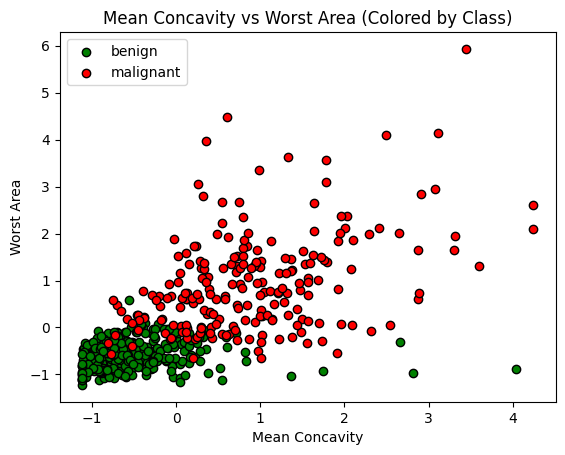

In [43]:
mean_concavity_i = np.where(dataset.feature_names == "mean concavity")
worst_area_i = np.where(dataset.feature_names == "worst area")

class_data = dataset.target == 1 # benign
plt.scatter(dataset.data_scaled[class_data, mean_concavity_i], dataset.data_scaled[class_data, worst_area_i],
             color="green", label=dataset.target_names[1], edgecolor='black')
class_data = dataset.target == 0 # malignant
plt.scatter(dataset.data_scaled[class_data, mean_concavity_i], dataset.data_scaled[class_data, worst_area_i],
             color="red", label=dataset.target_names[0], edgecolor='black')

plt.xlabel('Mean Concavity')
plt.ylabel('Worst Area')
plt.title('Mean Concavity vs Worst Area (Colored by Class)')
plt.legend()
plt.show() # note that this was done on the standardized data

4. Create a violinplot (plt.violinplot(..., showextrema=False)) of the features with highest
mean, highest median, highest variance (plot should have three vertical distributions). First calculate the
mean (np.mean(...)), median (np.median(...)), and variance (np.std(...)), then create the
violinplot of these three arrays

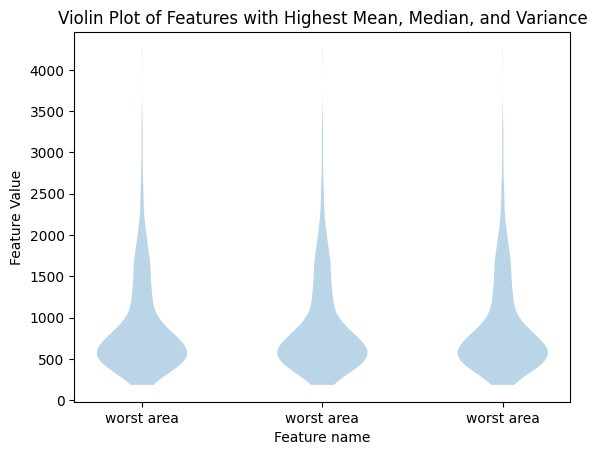

23 23 23


In [75]:
means = np.mean(dataset.data, axis = 0)
medians = np.median(dataset.data, axis = 0)
stds = np.std(dataset.data, axis = 0)

max_mean_index = np.argmax(means)
max_median_index = np.argmax(medians)
max_std_index = np.argmax(stds)

max_mean_f = dataset.data[:, max_mean_index]
max_median_f = dataset.data[:, max_median_index]
max_std_f = dataset.data[:, max_std_index]

plt.violinplot([max_mean_f, max_median_f, max_std_f], showextrema=False)
plt.title('Violin Plot of Features with Highest Mean, Median, and Variance')
plt.xticks([1, 2, 3], [dataset.feature_names[max_mean_index], dataset.feature_names[max_median_index], dataset.feature_names[max_std_index]])
plt.xlabel("Feature name")
plt.ylabel('Feature Value')
plt.show()

# for debugging:
print(max_mean_index, max_median_index, max_std_index)

5. Divide the data into a training and test set using train_test_split(data, targets,
test_size=0.2, shuffle=False). Train a logistic regression classifier
(LogisticRegression(..., max_iter=1e4), default parameters) on the training split and score
on the test split. What is the out-of-sample classification accuracy (ie accuracy on the unseen test data)?
How many iterations did it take for the model to converge (check the .n_iter_ attribute of the trained
model).

In [96]:
X_train, X_test, y_train, y_test = train_test_split(dataset.data, dataset.target, test_size=0.2, shuffle=False, random_state=42)
clf = LogisticRegression(max_iter=int(1e4), random_state=0).fit(X_train, y_train)
y_pred = clf.predict(X_test)

def print_res(clf):
    accuracy = accuracy_score(y_test, y_pred)
    print(f'Out-of-sample classification accuracy: {accuracy:.4f}')

    n_iter = clf.n_iter_[0]
    print(f'Number of iterations until convergence: {n_iter}')

print_res(clf)

Out-of-sample classification accuracy: 0.9298
Number of iterations until convergence: 2325


6. Create a pipeline model (make_pipeline(...)) that combines StandardScaler() followed by
the same logistic regression model as in 5, and train/test this pipeline model on the same data splits as
in 5. What is the out-of-sample classification accuracy now that the data is being standardized? How
many iterations did it take for the model to converge (to access the attributes of the logistic regression
model now that it’s part of a pipeline, use [your pipeline model].logisticregression)?
Notice the effect that scaling the data has.

In [97]:
pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=int(1e4), random_state=0))
pipeline

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=10000, random_state=0))])

In [99]:
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
print_res(pipeline.named_steps["logisticregression"])

Out-of-sample classification accuracy: 0.9825
Number of iterations until convergence: 18


Out of sample classification accuracy improved and number of iterations until convergence was reached significantly reduced (both of which are good) after scaling. 

7. Divide the data into training and test sets using KFold(n_splits=5, shuffle=False), and train
the pipeline model from 6 on each training split (you will re-train the model 5 times, once for each split).
Create a scatterplot of the test accuracies for each split (x-axis is the data splits, y-axis is accuracy).

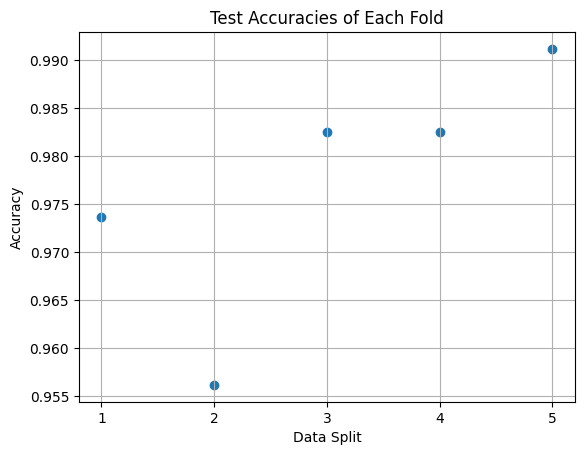

In [114]:
kf = KFold(n_splits=5, shuffle=False)
kfsplit = kf.split(dataset.data, dataset.target)

test_accuracies = []
for i, (train_index, test_index) in enumerate(kfsplit):
    X_train, X_test, y_train, y_test = dataset.data[train_index], dataset.data[test_index], dataset.target[train_index], dataset.target[test_index]

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    test_accuracies.append(accuracy_score(y_test, y_pred))

plt.scatter(range(1, 6), test_accuracies)
plt.title('Test Accuracies of Each Fold')
plt.xlabel('Data Split')
plt.ylabel('Accuracy')
plt.xticks(range(1, 6))
plt.grid(True)
plt.show()


8. Use LeaveOneOut() and the same pipeline model as in 6. Create a scatterplot of the test accuracies
for each split (the number of splits is now equal to the number of samples (rows).

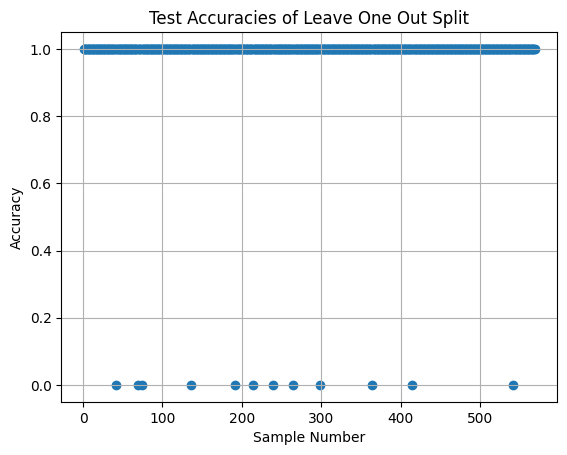

In [117]:
loo = LeaveOneOut()
test_accuracies = []

loo_split = loo.split(dataset.data, dataset.target)
for train_index, test_index in loo_split:
    X_train, X_test, y_train, y_test = dataset.data[train_index], dataset.data[test_index], dataset.target[train_index], dataset.target[test_index]
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    test_accuracies.append(accuracy_score(y_test, y_pred))

plt.scatter(range(1, len(test_accuracies) + 1), test_accuracies)
plt.title('Test Accuracies of Leave One Out Split')
plt.xlabel('Sample Number')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()
